# Preprocessing — boundaries and the 100 m protected-area buffer

This notebook prepares the **vector** layers the app needs (the raster/label work
lives in `prep.ipynb`). It produces three artefacts:

1. `ke.geojson` — Kenya county polygons (a static map backdrop).
2. `nrb.geojson` — the Nairobi county polygon (kept for reference).
3. **`data/raw/pa_100m_buffer.geojson`** — every protected-area polygon grown by a
   100 m buffer. This is the layer the encroachment metric intersects against, so
   that built-up growth *just outside* a boundary — the usual leading edge of
   encroachment — is counted, not just growth strictly inside the line.

Every code cell below is preceded by a short justification of *why* it is done that
way, so the notebook doubles as documentation.

## Paths and constants

Paths are **relative to the project root** (the notebook is run from there), not
absolute Windows paths, so the notebook is portable across machines. We fix the
metric CRS to **UTM zone 37S (EPSG:32737)** for all of Kenya: buffering must be done
in a projected CRS whose units are metres, because a 100 m buffer is meaningless in
degrees, and 37S is the zone that best covers the target areas around Nairobi.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
KE_COUNTIES = ROOT / "data" / "raw" / "ke.json"
PA_PATH     = ROOT / "data" / "raw" / "unep-wcmc and iucn protected areas" / "protected_conserved_areas_wdpca_polygons.geojson"
PA_BUFFER_OUT = ROOT / "data" / "raw" / "pa_100m_buffer.geojson"

WGS84 = "EPSG:4326"
METRIC_CRS = "EPSG:32737"   # UTM 37S, metres — required for a metric buffer
BUFFER_M = 100

ASSETS = ROOT / "assets" / "preprocessing" / "images"; ASSETS.mkdir(parents=True, exist_ok=True)

## Load and export county boundaries

The GADM county file (`ke.json`) is the authoritative admin-boundary source. We
re-export it as `ke.geojson` (and the Nairobi polygon as `nrb.geojson`) so the app
loads a single, clean GeoJSON rather than parsing the larger raw file at runtime.
These writes are idempotent — safe to re-run.

In [2]:
ke = gpd.read_file(KE_COUNTIES)
print("counties:", len(ke), "| CRS:", ke.crs)
ke.to_file(ROOT / "ke.geojson", driver="GeoJSON")
ke[ke["name"] == "Nairobi"].to_file(ROOT / "nrb.geojson", driver="GeoJSON")
print("wrote ke.geojson, nrb.geojson")

counties: 47 | CRS: EPSG:4326


wrote ke.geojson, nrb.geojson


## Load protected areas

The WDPA polygon layer is the reference boundary set. We inspect its CRS and the
`name`/`desig_eng` fields — the two used to locate specific parks downstream.

In [3]:
pa = gpd.read_file(PA_PATH)
print("PA polygons:", len(pa), "| CRS:", pa.crs)
pa[["name", "desig_eng"]].head()

PA polygons: 411 | CRS: EPSG:3857


,name,desig_eng
0,Tsavo East,National Park
1,Marsabit,National Reserve
2,Sibiloi,National Park
3,Meru,National Park
4,Aberdare,National Park


## Build and save the 100 m buffer (all protected areas)

The buffer is computed in the **metric CRS** so `.buffer(100)` means 100 metres. We
buffer every PA polygon once and persist the result to `pa_100m_buffer.geojson`.
Doing this here (rather than on every app request) keeps the runtime path fast and
makes the buffer an inspectable, versioned artefact. The saved file keeps the `name`
column so the encroachment step can still attribute change to individual PAs.

In [4]:
pa_m = pa.to_crs(METRIC_CRS)
pa_buf = pa_m[["name", "geometry"]].copy()
pa_buf["geometry"] = pa_m.buffer(BUFFER_M)
pa_buf.to_file(PA_BUFFER_OUT, driver="GeoJSON")
print(f"wrote {PA_BUFFER_OUT.name}: {len(pa_buf)} buffered polygons in {pa_buf.crs}")

wrote pa_100m_buffer.geojson: 411 buffered polygons in EPSG:32737


## Visual check — buffer around the two target AOIs

The app is scoped to **Nairobi National Park** and **Karura Forest Reserve**, so we
sanity-check the buffer on exactly those. The thin ring between the light (original
PA) and outlined (buffered) polygon is the 100 m margin that will now be included in
the encroachment calculation. We save the figure to `assets/` as documentation.

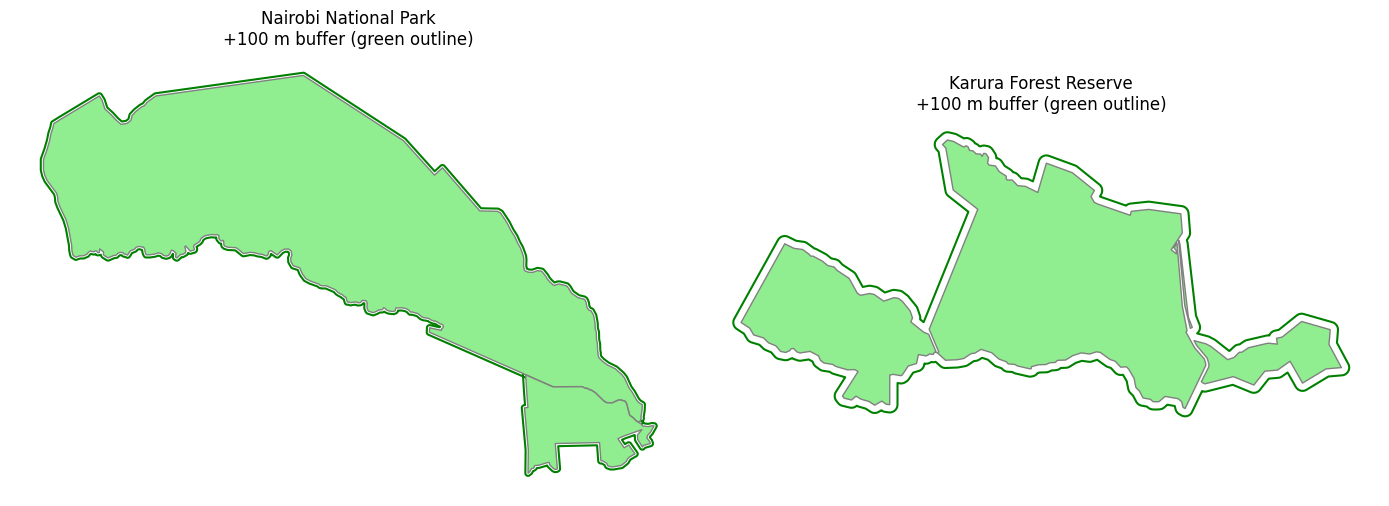

In [5]:
def find_pa(match, desig=None):
    sub = pa_m[pa_m["name"].str.contains(match, case=False, na=False)]
    if desig is not None and (sub["desig_eng"] == desig).any():
        sub = sub[sub["desig_eng"] == desig]
    return sub

targets = [("Nairobi National Park", "Nairobi", "National Park"),
           ("Karura Forest Reserve", "Karura", "Forest Reserve")]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (label, match, desig) in zip(axes, targets):
    src = find_pa(match, desig)
    ring = src.copy(); ring["geometry"] = src.buffer(BUFFER_M)
    ring.plot(ax=ax, color="none", edgecolor="green", linewidth=1.5)
    src.plot(ax=ax, color="lightgreen", edgecolor="grey")
    ax.set_title(f"{label}\n+100 m buffer (green outline)")
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(ASSETS / "01-target-pa-buffers.png", dpi=110, bbox_inches="tight")
plt.show()

## Kenya-wide view

For context, the full protected-area estate of Kenya with its 100 m buffer over the
county base map — confirming the buffer layer is complete and correctly projected.

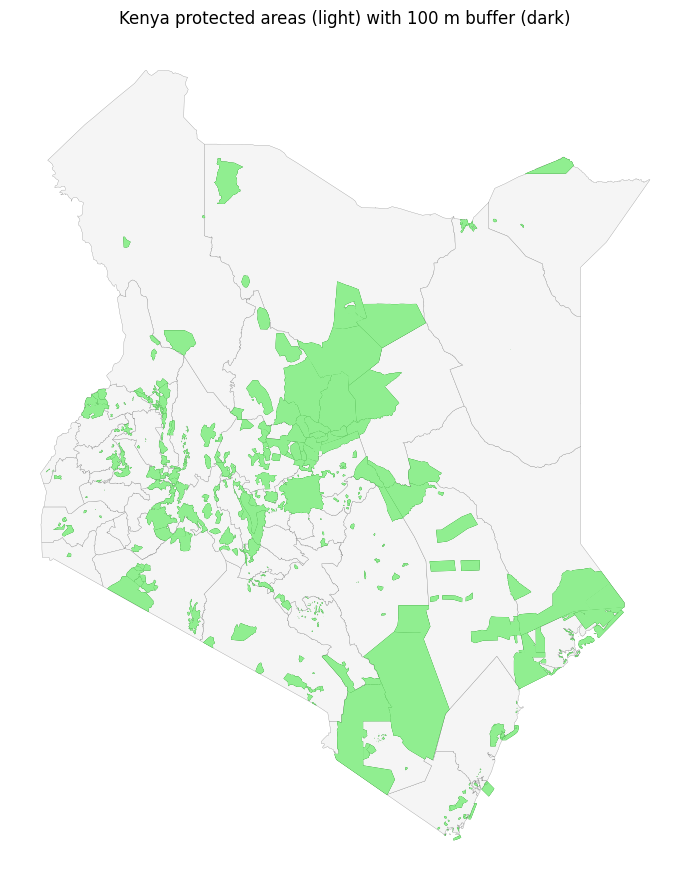

In [6]:
fig, ax = plt.subplots(figsize=(11, 11))
ke.to_crs(METRIC_CRS).plot(ax=ax, color="whitesmoke", edgecolor="grey", linewidth=0.2)
pa_buf.plot(ax=ax, color="green")
pa_m.plot(ax=ax, color="lightgreen")
ax.set_title("Kenya protected areas (light) with 100 m buffer (dark)")
ax.set_axis_off()
fig.savefig(ASSETS / "02-kenya-pa-buffers.png", dpi=110, bbox_inches="tight")
plt.show()